# CatDSGE parameter experiments

Checks of the CatDSGE steady state and solution away from the default calibration, and sweeps of the response to capital destruction across its key parameters.

In [1]:
import logging

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

from cycler import cycler
from matplotlib.colors import LogNorm, Normalize, TwoSlopeNorm
from matplotlib.ticker import PercentFormatter

import gEconpy as ge
import gEconpy.plotting as gp

from gEconpy.exceptions import SteadyStateNotFoundError

from climate_risk.dsge.model_files import resolve_gcn_path
from climate_risk.plotting import configure_plot_style

configure_plot_style(add_grid=True)
logging.getLogger("gEconpy").setLevel(logging.WARNING)

In [2]:
model = ge.model_from_gcn(resolve_gcn_path(variant="nonlinear"),
                          verbose=False)
parameters = model.parameters()

## 1. Steady state under trend inflation

A steady state exists only while every Calvo growth factor is below 1. The residual check must also reject a trend-inflation steady state with any one term reset to its zero-inflation value.

In [3]:
no_indexation = {"gamma_H": 0.0, "gamma_M": 0.0, "gamma_X": 0.0, "gamma_w": 0.0}

stress_calibrations = {"default": {},
                       "trend inflation 5%": {"pi_bar": 1.05},
                       "deflation 2%": {"pi_bar": 0.98},
                       "no indexation, 3%": {"pi_bar": 1.03, **no_indexation},
                       "extreme": {"pi_bar": 1.08,
                                   "gamma_H": 0.2,
                                   "gamma_M": 0.7,
                                   "gamma_X": 0.1,
                                   "gamma_w": 0.6,
                                   "chi": 2.5,
                                   "sigma": 3.5,
                                   "phi_H": 0.8,
                                   "psi_w": 6.0,
                                   "theta_w": 0.4,
                                   "psi_H": 8.0,
                                   "theta_H": 0.5,
                                   "psi_M": 6.0,
                                   "theta_M": 0.6,
                                   "psi_X": 3.0,
                                   "theta_X": 0.4,
                                   "psi_Y": 2.0,
                                   "alpha_Y": 0.6,
                                   "tau_L": 0.3,
                                   "tau_M": 0.2,
                                   "tau_X": 0.1}}


def largest_calvo_growth_factor(updates):
    """Return the largest theta * (pi_bar^(1 - gamma))^exponent across the Calvo sums. A steady state exists only below 1."""
    values = model.parameters(**updates)

    def gap(sector):
        return values["pi_bar"] ** (1 - values[f"gamma_{sector}"])

    return max(values["theta_H"] * gap("H") ** values["psi_H"],
               values["theta_M"] * gap("M") ** values["psi_M"],
               values["theta_X"] * gap("X") ** values["psi_X"],
               values["theta_w"] * gap("w") ** (values["psi_w"] * (1 + values["chi"])))


for updates in stress_calibrations.values():
    ge.check_steady_state(model, **updates)

pd.Series({name: largest_calvo_growth_factor(updates) for name, updates in stress_calibrations.items()},
          name="largest Calvo growth factor").to_frame()

Steady state successfully found!
Steady state successfully found!
Steady state successfully found!
Steady state successfully found!
Steady state successfully found!


,largest Calvo growth factor
default,0.50
trend inflation 5%,0.64
deflation 2%,0.48
"no indexation, 3%",0.67
extreme,0.82


In [4]:
trend_inflation_ss = model.steady_state(verbose=False, pi_bar=1.05)
zero_inflation_ss = model.steady_state(verbose=False)

trend_inflation_terms = ["nu_H", "nu_M", "nu_X", "nu_w", "p_H_tilde", "p_M_tilde", "p_X_tilde", "w_tilde",
                         "mu_H", "p_M", "p_X", "L", "x_1", "x_2", "z_1_M", "z_2_M", "z_1_X", "z_2_X", "x_1_w", "x_2_w"]


def is_caught(term):
    """Reset one steady-state value to its zero-inflation level and report whether the residual check fails."""
    mutated_ss = trend_inflation_ss.copy()
    mutated_ss[f"{term}_ss"] = zero_inflation_ss[f"{term}_ss"]
    try:
        ge.check_steady_state(model, steady_state=mutated_ss, pi_bar=1.05)
    except SteadyStateNotFoundError:
        return True
    return False


mutation_check = pd.DataFrame({"pi_bar = 1.05": {term: trend_inflation_ss[f"{term}_ss"] for term in trend_inflation_terms},
                               "pi_bar = 1": {term: zero_inflation_ss[f"{term}_ss"] for term in trend_inflation_terms},
                               "mutation caught": {term: is_caught(term) for term in trend_inflation_terms}})
mutation_check.style.format(precision=4)

,pi_bar = 1.05,pi_bar = 1,mutation caught
nu_H,1.0029,1.0000,True
nu_M,1.0029,1.0000,True
nu_X,1.0029,1.0000,True
nu_w,1.0620,1.0000,True
p_H_tilde,1.0267,1.0000,True
p_M_tilde,1.0267,1.0000,True
p_X_tilde,1.0267,1.0000,True
w_tilde,0.2395,0.2332,True
mu_H,0.3973,0.3971,True
p_M,1.4664,1.4667,True


## 2. Determinacy and persistence

Blanchard-Kahn classification across trend inflation, with and without indexation, and the slowest eigenvalues of the solved transition matrix.

In [5]:
def classify_equilibrium(**updates):
    if largest_calvo_growth_factor(updates) >= 1:
        return "no steady state"

    eigenvalues = ge.check_bk_condition(model,
                                        verbose=False,
                                        return_value="dataframe",
                                        **updates)
    unstable_count = int((eigenvalues["Modulus"] > 1).sum())
    if unstable_count == model.n_forward:
        return "determinate"
    return "indeterminate" if unstable_count < model.n_forward else "explosive"


trend_inflation_grid = [1.0, 1.02, 1.03, 1.04, 1.05, 1.06, 1.08]

pd.DataFrame({"indexation 0.5": [classify_equilibrium(pi_bar=trend_inflation) for trend_inflation in trend_inflation_grid],
              "no indexation": [classify_equilibrium(pi_bar=trend_inflation, **no_indexation)
                                for trend_inflation in trend_inflation_grid]},
             index=pd.Index(trend_inflation_grid, name="pi_bar"))

,indexation 0.5,no indexation
pi_bar,,
1.00,determinate,determinate
1.02,determinate,determinate
1.03,determinate,determinate
1.04,determinate,indeterminate
1.05,determinate,indeterminate
1.06,determinate,indeterminate
1.08,determinate,no steady state


In [6]:
transition_matrix, _ = model.solve_model(verbose=False)
eigenvalue_moduli = np.sort(np.abs(np.linalg.eigvals(transition_matrix)))[::-1]
half_life = np.log(0.5) / np.log(eigenvalue_moduli[0])

print(f"half-life of the slowest eigenvalue: {half_life:.0f} years")
pd.Series(eigenvalue_moduli[:6],
          index=pd.RangeIndex(1, 7, name="rank"),
          name="eigenvalue modulus").to_frame().style.format(precision=4)

half-life of the slowest eigenvalue: 9 years


,eigenvalue modulus
rank,
1,0.9227
2,0.9227
3,0.9000
4,0.9000
5,0.9000
6,0.8967


## 3. Steady-state ratios and accounting identities

Great ratios at the default calibration, then the household and government budget residuals and the goods-market and external accounts, as shares of output.

In [7]:
globals().update({name: float(value) for name, value in model.steady_state(verbose=False).items()})
output = Y_ss

great_ratios = pd.Series({"consumption / output": C_ss / output,
                          "investment / output": I_ss / output,
                          "government spending / output": G_ss / output,
                          "exports / output": p_X_ss * X_ss / output,
                          "imports / output": p_M_ss * M_ss / output,
                          "government debt / output": B_ss / output,
                          "foreign debt / output": q_ss * B_star_ss / output,
                          "capital / output": K_ss / output,
                          "labor share": w_ss * L_ss / (p_H_ss * H_ss),
                          "policy rate": i_ss},
                         name="steady state")
great_ratios.to_frame().style.format(precision=3)

,steady state
consumption / output,0.501
investment / output,0.060
government spending / output,0.180
exports / output,0.174
imports / output,0.648
government debt / output,0.450
foreign debt / output,0.150
capital / output,0.597
labor share,0.525
policy rate,0.053


In [8]:
capital_services = r_ss * z_ss * xi_K_ss * K_ss
import_bill_world_prices = q_ss * p_M_star_ss * nu_M_ss * M_ss

profits = {"Pi_H": p_H_ss * (H_H_ss + nu_X_ss * X_ss) - capital_services - w_ss * L_ss,
           "Pi_X": (1 - tau_X_ss) * p_X_ss * X_ss - p_H_ss * nu_X_ss * X_ss,
           "Pi_M": p_M_ss * M_ss - (1 + tau_M_ss) * import_bill_world_prices}

taxes = (tau_C_ss * C_ss
         + tau_K_ss * capital_services
         + tau_L_ss * w_ss * L_ss
         + tau_M_ss * import_bill_world_prices
         + tau_X_ss * p_X_ss * X_ss)

lump_sum_tax = parameters["T_lump"]
domestic_bond_return = (1 + i_ss) / pi_ss * B_ss
foreign_bond_return = q_ss * R_star_given_ss / pi_star_ss * B_star_ss
net_foreign_income = foreign_bond_return - q_ss * B_star_ss

household_residual = ((1 - tau_K_ss) * capital_services
                      + (1 - tau_L_ss) * w_ss * L_ss
                      + domestic_bond_return
                      + foreign_bond_return
                      + sum(profits.values())
                      - lump_sum_tax
                      - (1 + tau_C_ss) * C_ss
                      - I_ss
                      - B_ss
                      - q_ss * B_star_ss)

government_residual = domestic_bond_return + G_ss - taxes - lump_sum_tax - B_ss

identities = pd.Series({"household budget residual": household_residual,
                        "government budget residual": government_residual,
                        "Y - C - I - G": Y_ss - C_ss - I_ss - G_ss,
                        "trade balance + net foreign income": p_X_ss * X_ss - import_bill_world_prices + net_foreign_income,
                        "of which exports": p_X_ss * X_ss,
                        "of which imports at world prices": -import_bill_world_prices,
                        "of which net foreign income": net_foreign_income})
(identities / output).to_frame("share of output").style.format(precision=4)

,share of output
household budget residual,0.0000
government budget residual,0.0000
Y - C - I - G,0.2598
trade balance + net foreign income,-0.2598
of which exports,0.1740
of which imports at world prices,-0.4417
of which net foreign income,0.0079


## 4. Impulse responses

Twenty-year responses to capital destruction, then to the remaining shocks together.

In [9]:
shock_sizes = {"epsilon_xi_K": -0.10,
               "epsilon_A": -0.01,
               "epsilon_xi_I": -0.01,
               "epsilon_p_M_star": 0.10,
               "epsilon_q": 0.05,
               "epsilon_G": 0.05,
               "epsilon_Y_star": -0.01,
               "epsilon_i": 0.0025}

irf = ge.impulse_response_function(model,
                                   simulation_length=20,
                                   shock_size=shock_sizes,
                                   verbose=False)

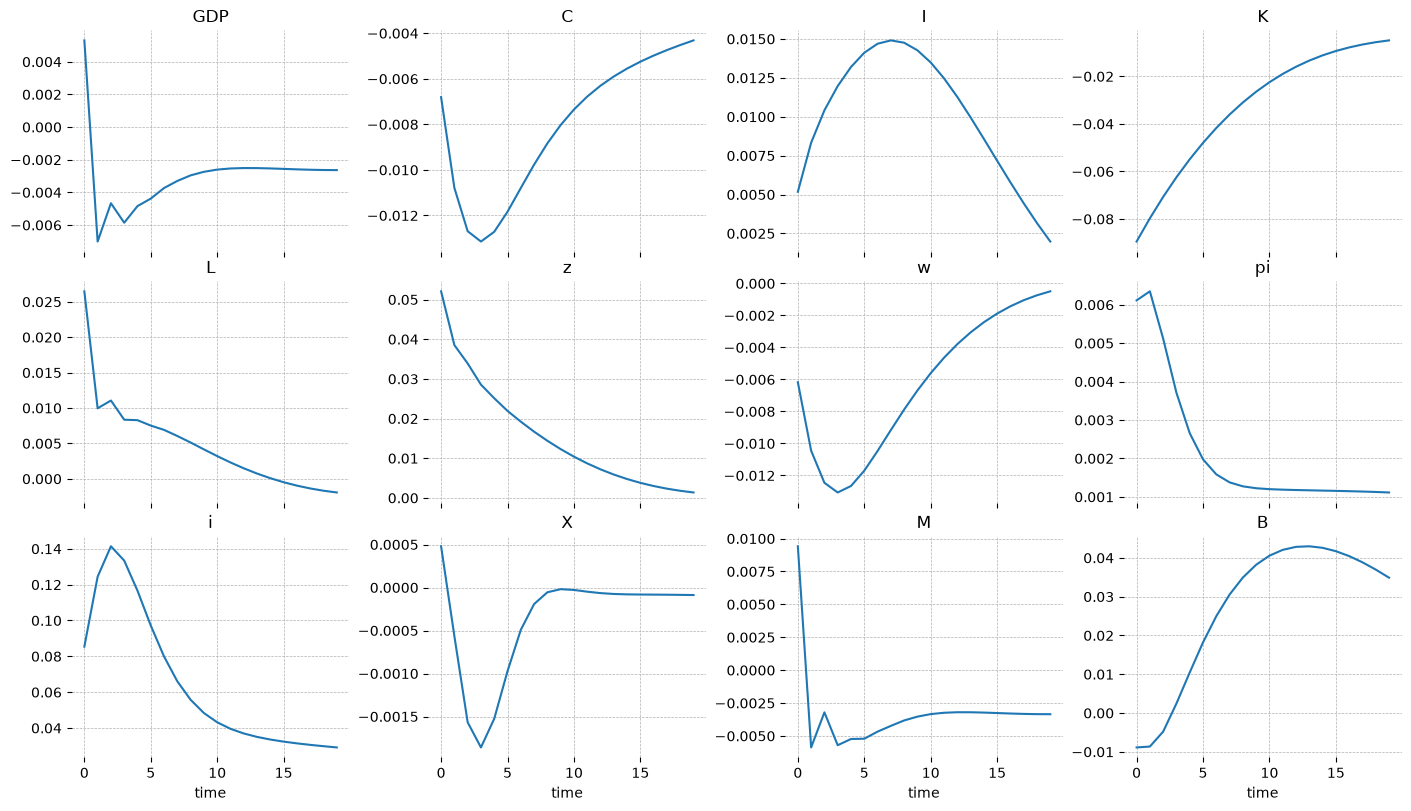

In [10]:
macro_variables = ["GDP", "C", "I", "K", "L", "z", "w", "pi", "i", "X", "M", "B"]

fig = gp.plot_irf(irf,
                  vars_to_plot=macro_variables,
                  shocks_to_plot="epsilon_xi_K",
                  n_cols=4,
                  figsize=(14, 8))

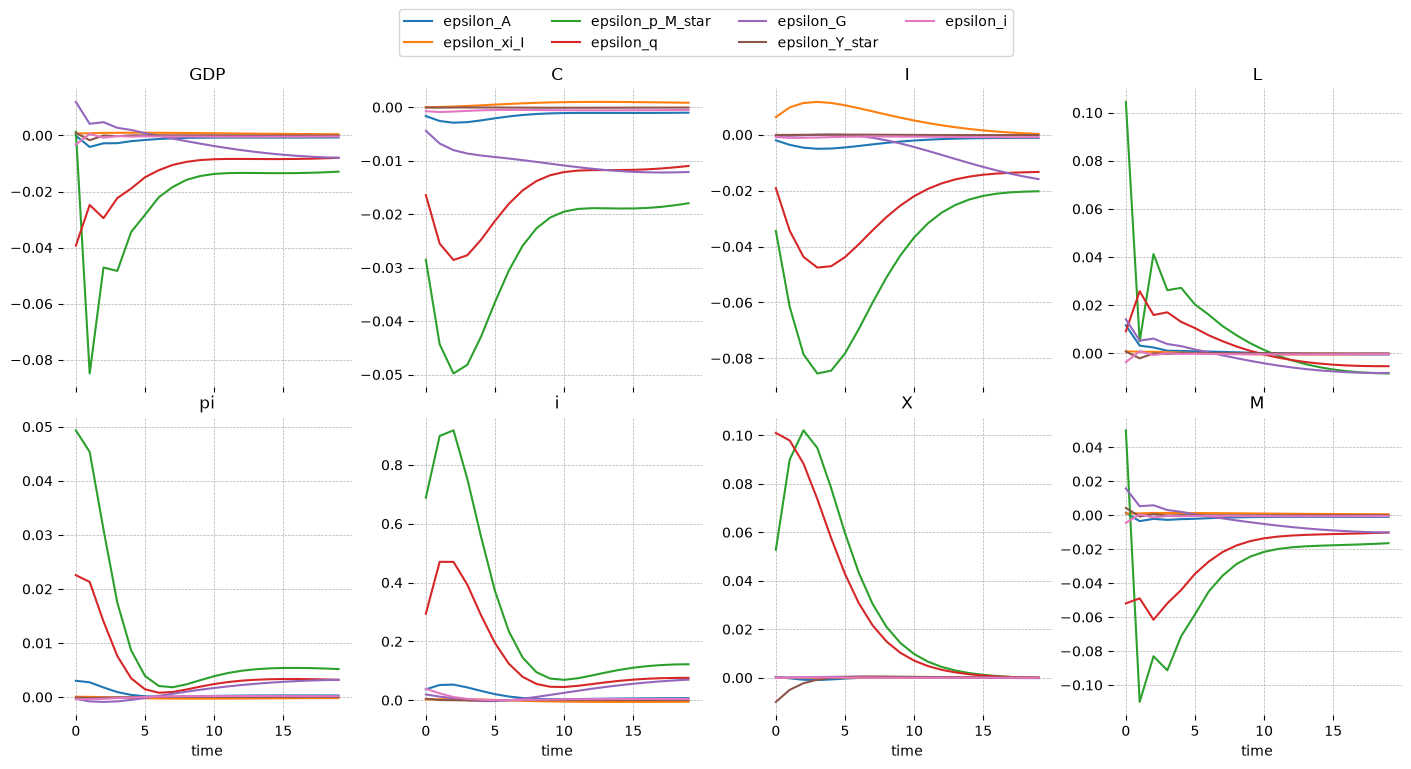

In [11]:
other_shocks = [shock_name for shock_name in shock_sizes if shock_name != "epsilon_xi_K"]

fig = gp.plot_irf(irf,
                  vars_to_plot=["GDP", "C", "I", "L", "pi", "i", "X", "M"],
                  shocks_to_plot=other_shocks,
                  n_cols=4,
                  legend=True,
                  figsize=(14, 7))

## 5. Import price shock

How a 10% rise in world import prices passes through the model, and the expenditure contributions to output, in percent over the first six years.

In [12]:
import_price_irf = irf.sel(shock="epsilon_p_M_star").to_pandas()

import_price_chain = ["p_M_star", "p_M", "pi_M", "nu_M", "pi", "p_H", "M", "H_H", "Y", "GDP", "H", "L", "z",
                      "C", "I", "G", "X", "q", "B_star", "Phi_B", "B", "i", "lambda", "tau_L"]

(100 * import_price_irf.loc[:5, import_price_chain]).T

time,0,1,2,3,4,5
variable,,,,,,
p_M_star,10.00,7.00,4.90,3.43,2.40,1.68
p_M,1.78,3.11,3.45,3.16,2.58,1.98
pi_M,6.71,5.87,3.44,1.45,0.29,-0.21
nu_M,0.00,0.00,0.00,0.00,0.00,0.00
pi,4.93,4.53,3.10,1.74,0.86,0.39
p_H,-3.27,-5.73,-6.35,-5.81,-4.75,-3.64
M,5.00,-11.00,-8.31,-9.14,-7.13,-5.84
H_H,9.03,-3.92,-0.46,-1.96,-1.26,-1.35
Y,6.42,-8.51,-5.55,-6.61,-5.06,-4.26


In [13]:
import_bill_share = (1 + tau_M_ss) * q_ss * p_M_star_ss * M_ss / output
export_share = p_X_ss * X_ss / output

import_price_contributions = pd.DataFrame({"Y": import_price_irf["Y"],
                                           "C": C_ss / output * import_price_irf["C"],
                                           "I": I_ss / output * import_price_irf["I"],
                                           "G": G_ss / output * import_price_irf["G"],
                                           "exports": export_share * (import_price_irf["p_X"] + import_price_irf["X"]),
                                           "import bill": import_bill_share * (import_price_irf["q"]
                                                                               + import_price_irf["p_M_star"]
                                                                               + import_price_irf["M"])})
100 * import_price_contributions.loc[:5]

,Y,C,I,G,exports,import bill
time,,,,,,
0,6.42,-1.43,-0.21,-0.00,0.31,7.29
1,-8.51,-2.22,-0.37,-0.00,0.52,-1.94
2,-5.55,-2.49,-0.47,-0.00,0.59,-1.66
3,-6.61,-2.41,-0.51,-0.00,0.55,-2.77
4,-5.06,-2.15,-0.50,-0.00,0.45,-2.30
5,-4.26,-1.83,-0.47,-0.00,0.35,-2.02


## 6. Decomposing the capital destruction response

Contributions to the GDP response over the first five years, from the expenditure side and then the supply side, in percent.

In [14]:
destruction_irf = irf.sel(shock="epsilon_xi_K").to_pandas()

gdp_contributions = pd.DataFrame({"C": C_ss / GDP_ss * destruction_irf["C"],
                                  "I": I_ss / GDP_ss * destruction_irf["I"],
                                  "G": G_ss / GDP_ss * destruction_irf["G"],
                                  "utilization cost": parameters["psi_z_1"] * K_ss / GDP_ss * destruction_irf["z"]})
gdp_contributions["external flows"] = destruction_irf["GDP"] - gdp_contributions.sum(axis=1)
gdp_contributions["GDP"] = destruction_irf["GDP"]

100 * gdp_contributions.loc[:4]

,C,I,G,utilization cost,external flows,GDP
time,,,,,,
0,-0.47,0.04,0.00,0.65,0.31,0.53
1,-0.74,0.07,0.00,0.48,-0.51,-0.70
2,-0.87,0.08,0.00,0.42,-0.11,-0.47
3,-0.90,0.10,0.00,0.36,-0.14,-0.59
4,-0.87,0.11,0.00,0.31,-0.03,-0.48


In [15]:
installed_capital = destruction_irf["K"].shift(1, fill_value=0.0)

supply_side = pd.DataFrame({"capital services": parameters["alpha"] * (destruction_irf["z"]
                                                                       + destruction_irf["xi_K"]
                                                                       + installed_capital),
                            "hours": (1 - parameters["alpha"]) * destruction_irf["L"],
                            "home production H": destruction_irf["H"]})
100 * supply_side.loc[:4]

,capital services,hours,home production H
time,,,
0,-1.44,1.85,0.42
1,-1.53,0.70,-0.83
2,-1.37,0.77,-0.60
3,-1.26,0.58,-0.68
4,-1.12,0.58,-0.54


## 7. Sensitivity of the capital destruction response

Responses to 10% capital destruction across grids of one parameter at a time. Every sweep after the first two holds $\chi = 4$.

In [16]:
SWEEP_VARIABLES = {"GDP": "GDP",
                   "C": "consumption",
                   "I": "investment",
                   "K": "capital",
                   "L": "hours",
                   "z": "utilization",
                   "w": "real wage",
                   "pi": "inflation"}


def sweep_irfs(parameter, grid, shock_name, fixed_parameters=None):
    fixed_parameters = fixed_parameters or {}
    irfs = [ge.impulse_response_function(model,
                                         simulation_length=20,
                                         shock_size={shock_name: shock_sizes[shock_name]},
                                         verbose=False,
                                         **fixed_parameters,
                                         **{parameter: value})
            for value in grid]
    return xr.concat(irfs, dim=parameter).assign_coords({parameter: grid})


def plot_sweep(irfs, parameter, shock_name, norm, title):
    colors = [plt.colormaps["viridis"](norm(value)) for value in irfs[parameter].values]

    fig, ax = plt.subplots(2, 4, figsize=(14, 6), sharex=True)
    for axis, (variable, label) in zip(ax.flat, SWEEP_VARIABLES.items(), strict=True):
        axis.set_prop_cycle(cycler("color", colors))
        irfs.sel(variable=variable, shock=shock_name).plot.line(x="time", hue=parameter, add_legend=False, ax=axis)
        axis.axhline(0, ls="--", c="k", lw=0.8)
        axis.yaxis.set_major_formatter(PercentFormatter(xmax=1))
        axis.set(title=label,
                 xlabel="years" if axis in ax[-1, :] else "",
                 ylabel="deviation from steady state" if axis in ax[:, 0] else "")

    colorbar = fig.colorbar(plt.cm.ScalarMappable(cmap="viridis", norm=norm), ax=ax)
    colorbar.set_label(rf"$\{parameter}$")
    fig.suptitle(title, x=0.02, ha="left")
    return fig

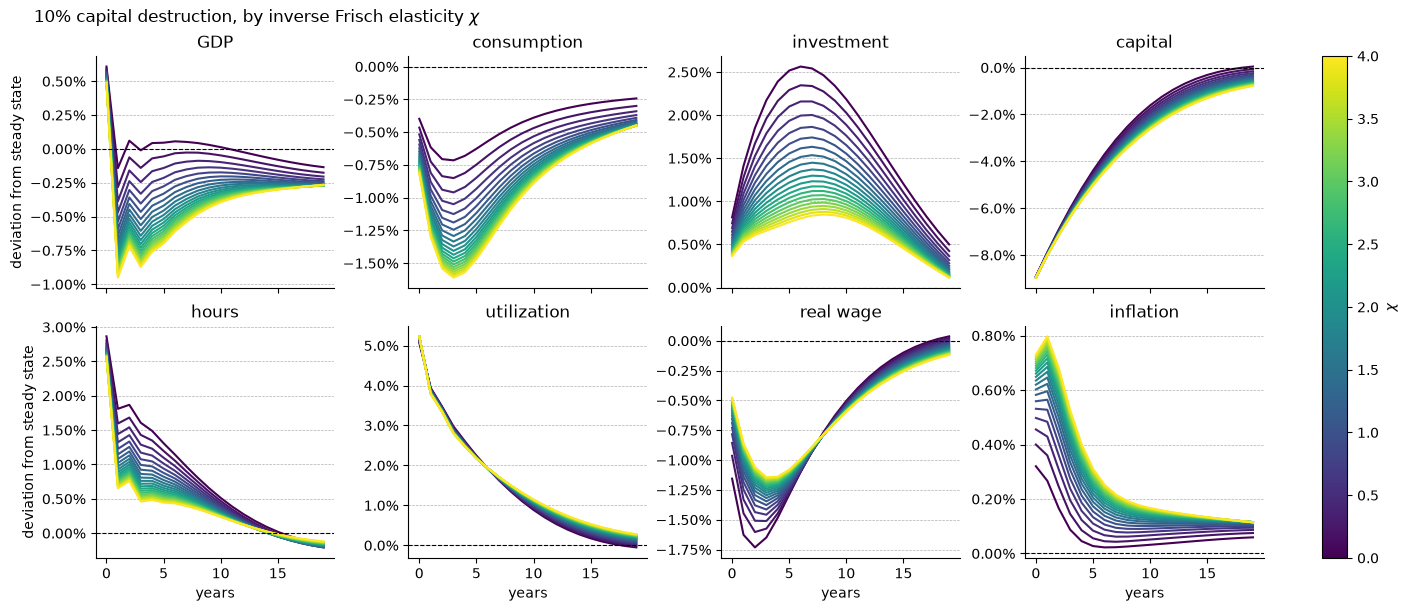

In [17]:
chi_grid = np.linspace(0.0, 4.0, 21)
chi_irfs = sweep_irfs(parameter="chi",
                      grid=chi_grid,
                      shock_name="epsilon_xi_K")

fig = plot_sweep(irfs=chi_irfs,
                 parameter="chi",
                 shock_name="epsilon_xi_K",
                 norm=Normalize(vmin=chi_grid.min(), vmax=chi_grid.max()),
                 title=r"10% capital destruction, by inverse Frisch elasticity $\chi$")
plt.show()

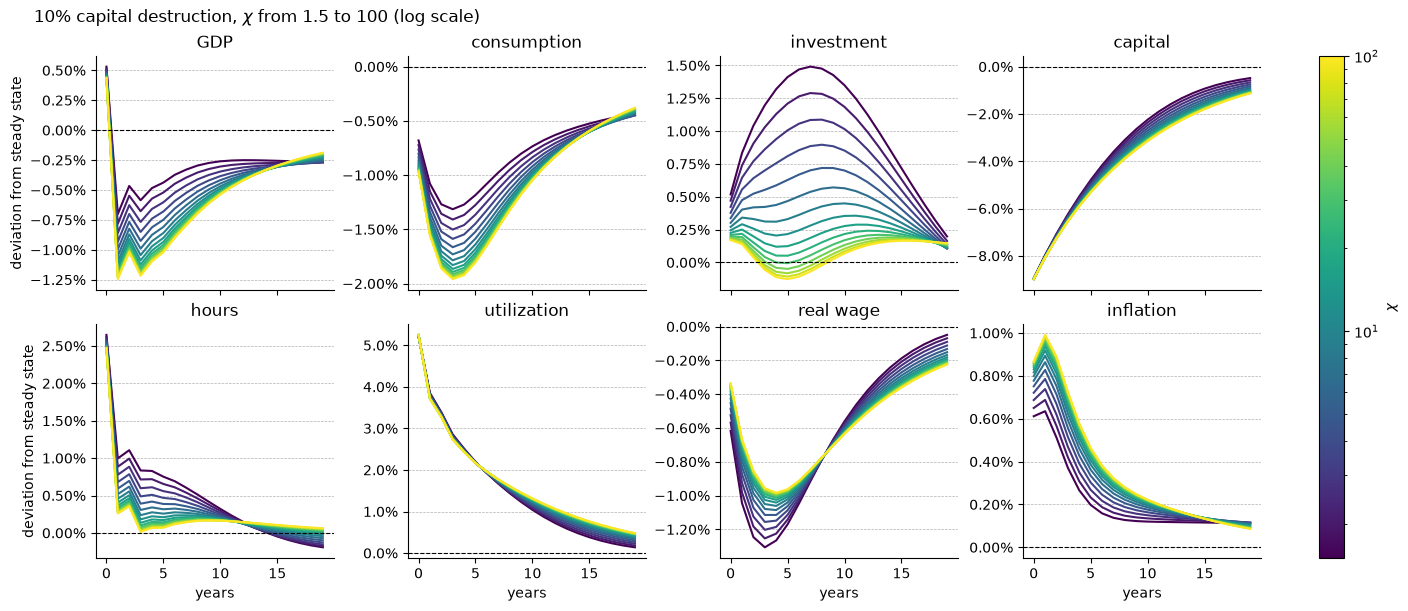

In [18]:
high_chi_grid = np.geomspace(1.5, 100.0, 15)
high_chi_irfs = sweep_irfs(parameter="chi",
                           grid=high_chi_grid,
                           shock_name="epsilon_xi_K")

fig = plot_sweep(irfs=high_chi_irfs,
                 parameter="chi",
                 shock_name="epsilon_xi_K",
                 norm=LogNorm(vmin=high_chi_grid.min(), vmax=high_chi_grid.max()),
                 title=r"10% capital destruction, $\chi$ from 1.5 to 100 (log scale)")
plt.show()

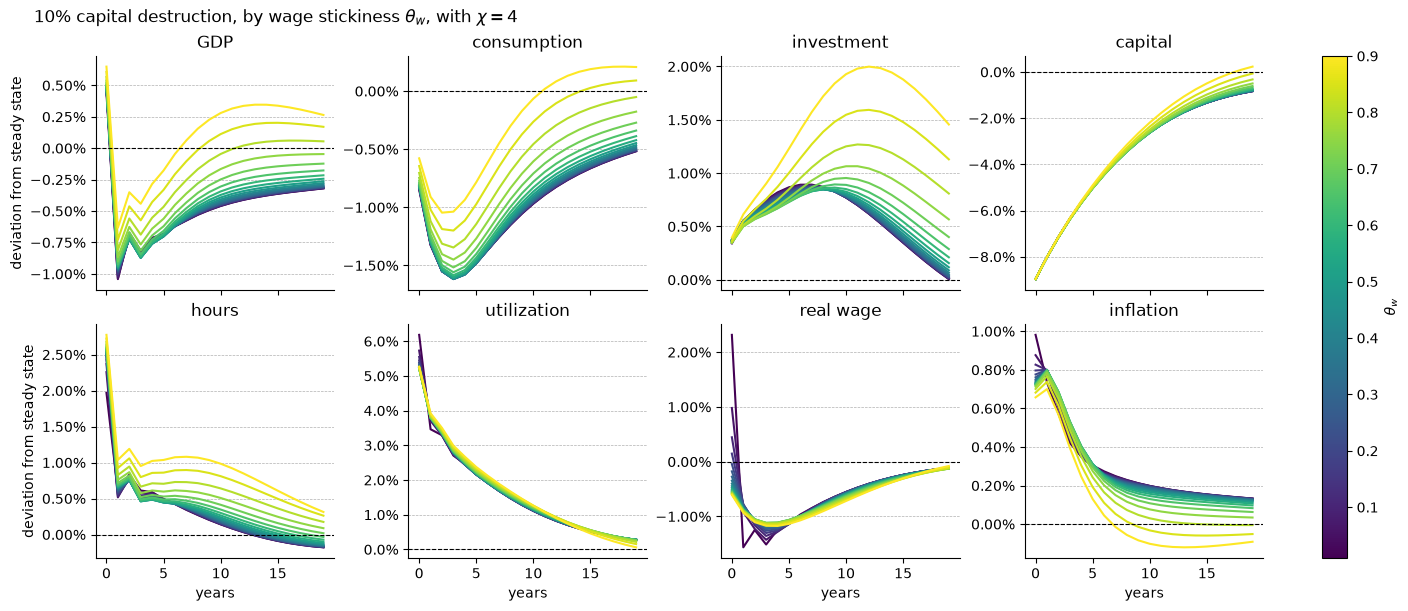

In [19]:
theta_w_grid = np.linspace(0.01, 0.9, 19)
theta_w_irfs = sweep_irfs(parameter="theta_w",
                          grid=theta_w_grid,
                          shock_name="epsilon_xi_K",
                          fixed_parameters={"chi": 4.0})

fig = plot_sweep(irfs=theta_w_irfs,
                 parameter="theta_w",
                 shock_name="epsilon_xi_K",
                 norm=Normalize(vmin=theta_w_grid.min(), vmax=theta_w_grid.max()),
                 title=r"10% capital destruction, by wage stickiness $\theta_w$, with $\chi = 4$")
plt.show()

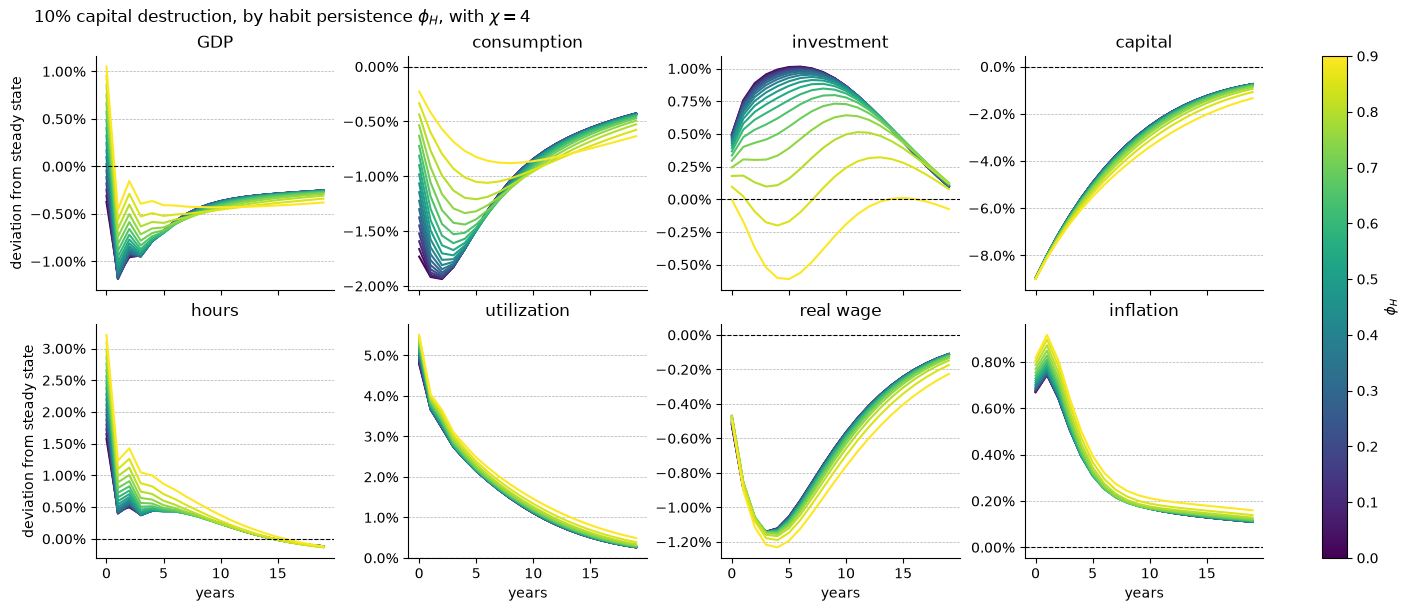

In [20]:
phi_H_grid = np.linspace(0.0, 0.9, 19)
phi_H_irfs = sweep_irfs(parameter="phi_H",
                        grid=phi_H_grid,
                        shock_name="epsilon_xi_K",
                        fixed_parameters={"chi": 4.0})

fig = plot_sweep(irfs=phi_H_irfs,
                 parameter="phi_H",
                 shock_name="epsilon_xi_K",
                 norm=Normalize(vmin=phi_H_grid.min(), vmax=phi_H_grid.max()),
                 title=r"10% capital destruction, by habit persistence $\phi_H$, with $\chi = 4$")
plt.show()

In [21]:
phi_H_impact = phi_H_irfs.sel(shock="epsilon_xi_K", time=0, variable=["GDP", "C", "L", "I"]).to_pandas()
100 * phi_H_impact

variable,GDP,C,L,I
phi_H,,,,
0.00,-0.37,-1.73,1.58,0.50
0.05,-0.31,-1.66,1.65,0.49
0.10,-0.25,-1.59,1.73,0.49
0.15,-0.18,-1.52,1.80,0.48
0.20,-0.11,-1.45,1.88,0.48
0.25,-0.04,-1.37,1.96,0.47
0.30,0.03,-1.30,2.04,0.46
0.35,0.10,-1.22,2.12,0.45
0.40,0.17,-1.14,2.20,0.44


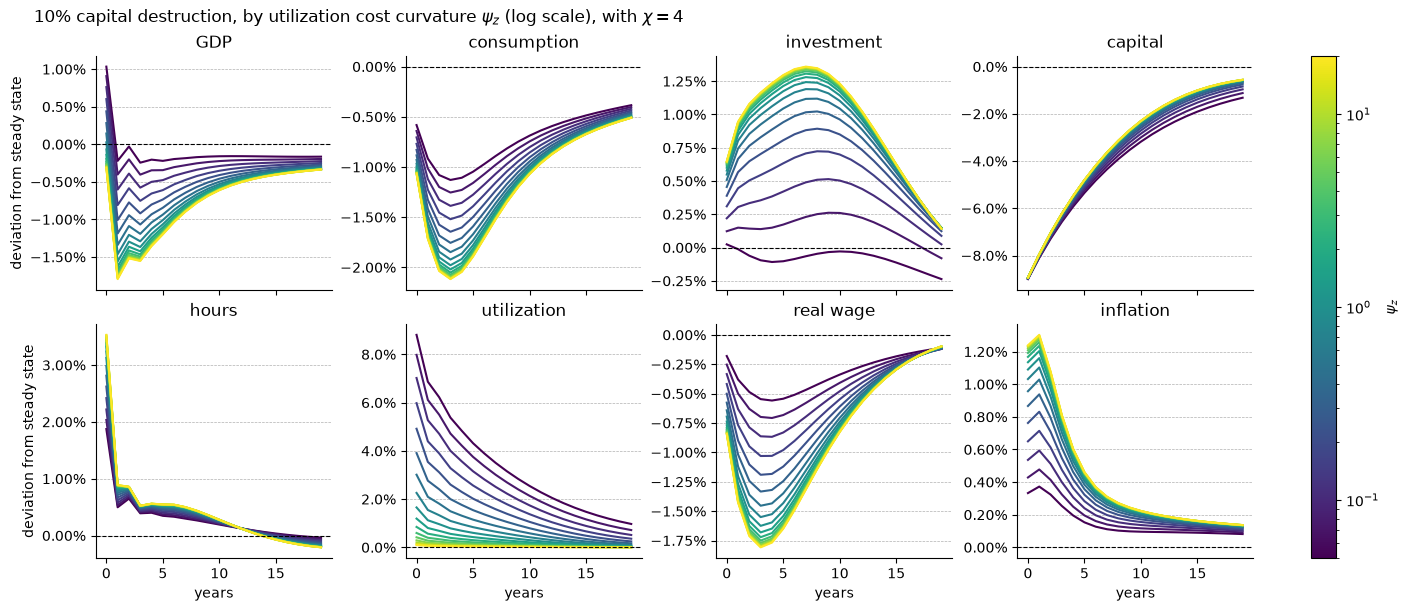

In [22]:
psi_z_grid = np.geomspace(0.05, 20.0, 17)
psi_z_irfs = sweep_irfs(parameter="psi_z",
                        grid=psi_z_grid,
                        shock_name="epsilon_xi_K",
                        fixed_parameters={"chi": 4.0})

fig = plot_sweep(irfs=psi_z_irfs,
                 parameter="psi_z",
                 shock_name="epsilon_xi_K",
                 norm=LogNorm(vmin=psi_z_grid.min(), vmax=psi_z_grid.max()),
                 title=r"10% capital destruction, by utilization cost curvature $\psi_z$ (log scale), with $\chi = 4$")
plt.show()

In [23]:
psi_z_impact = psi_z_irfs.sel(shock="epsilon_xi_K", time=0, variable=["GDP", "C", "L", "I", "z"]).to_pandas()
100 * psi_z_impact

variable,GDP,C,L,I,z
psi_z,,,,,
0.05,1.03,-0.58,1.87,0.02,8.81
0.07,0.91,-0.64,2.03,0.12,7.98
0.11,0.76,-0.70,2.22,0.22,7.02
0.15,0.60,-0.77,2.42,0.31,5.98
0.22,0.44,-0.83,2.62,0.39,4.92
0.33,0.28,-0.88,2.81,0.46,3.91
0.47,0.14,-0.93,2.98,0.51,3.01
0.69,0.03,-0.97,3.13,0.55,2.26
1.00,-0.07,-1.00,3.24,0.58,1.66


### Habit persistence and utilization cost together

The impact response of GDP over a joint grid of $\phi_H$ and $\psi_z$. The contour marks where it changes sign.

In [24]:
def impact_response(variable, shock_name, **updates):
    _, selection_matrix = model.solve_model(verbose=False, **updates)
    impact_matrix = ge.matrix_to_dataframe(selection_matrix, model)
    return impact_matrix.loc[variable, shock_name] * shock_sizes[shock_name]


joint_phi_H_grid = np.linspace(0.0, 0.9, 15)
joint_psi_z_grid = np.geomspace(0.05, 20.0, 15)

impact_gdp = xr.DataArray([[impact_response("GDP", "epsilon_xi_K", chi=4.0, phi_H=phi_H, psi_z=psi_z)
                            for phi_H in joint_phi_H_grid]
                           for psi_z in joint_psi_z_grid],
                          dims=["psi_z", "phi_H"],
                          coords={"psi_z": joint_psi_z_grid, "phi_H": joint_phi_H_grid})

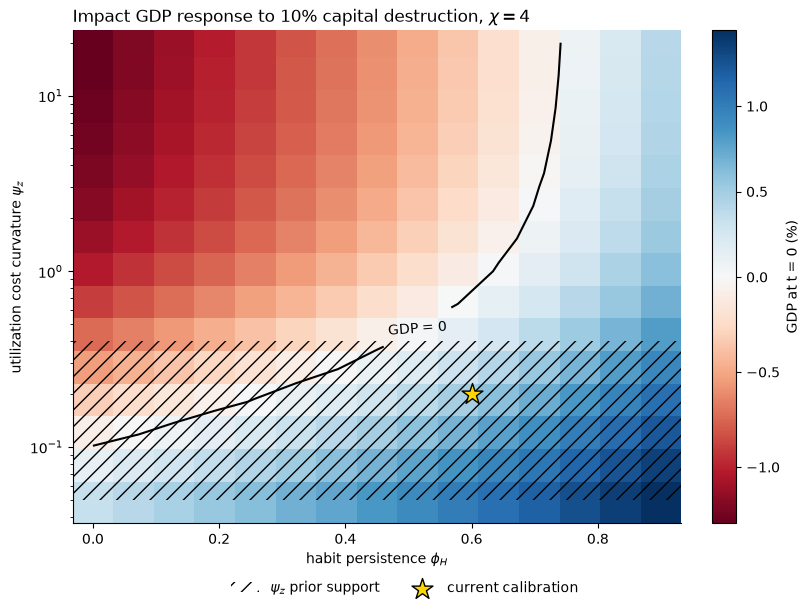

In [25]:
PSI_Z_PRIOR_SUPPORT = (0.05, 0.40)

fig, ax = plt.subplots(figsize=(8, 6))
mesh = ax.pcolormesh(joint_phi_H_grid,
                     joint_psi_z_grid,
                     100 * impact_gdp.values,
                     cmap="RdBu",
                     norm=TwoSlopeNorm(vcenter=0.0),
                     shading="auto")
contour = ax.contour(joint_phi_H_grid,
                     joint_psi_z_grid,
                     impact_gdp.values,
                     levels=[0.0],
                     colors="k",
                     linewidths=1.5)
ax.clabel(contour, fmt={0.0: "GDP = 0"})

ax.axhspan(*PSI_Z_PRIOR_SUPPORT,
           facecolor="none",
           edgecolor="k",
           hatch="//",
           lw=0.0,
           label=r"$\psi_z$ prior support")
ax.scatter(parameters["phi_H"],
           parameters["psi_z"],
           marker="*",
           s=250,
           color="gold",
           edgecolor="k",
           zorder=10,
           label="current calibration")

ax.set(yscale="log",
       xlabel=r"habit persistence $\phi_H$",
       ylabel=r"utilization cost curvature $\psi_z$")
ax.set_title(r"Impact GDP response to 10% capital destruction, $\chi = 4$", loc="left")
ax.grid(visible=False)
fig.colorbar(mesh, ax=ax, label="GDP at t = 0 (%)")
fig.legend(loc="outside lower center", ncol=2, frameon=False)
plt.show()

## 8. Estimates for India

Estimates from two Indian DSGE studies, converted to CatDSGE's parameterization and to annual frequency, next to the current calibration.

In [26]:
COMPARED_PARAMETERS = ["phi_H", "chi", "psi_z", "theta_H", "gamma_H", "theta_w", "phi_pi", "rho_i", "rho_G"]
utilization_rental_rate = parameters["psi_z_1"]


def quarterly_to_annual(value):
    return value ** 4


def sharma_behera_psi_z(curvature):
    # Depreciation-in-use delta(U) with delta''/delta' = phi_u at U = 1
    return curvature * utilization_rental_rate


def leeper_psi_z(psi):
    # Leeper, Traum and Walker (2017) normalization: a''/a' = psi / (1 - psi)
    return psi / (1 - psi) * utilization_rental_rate


def interval(center, low, high, transform=lambda value: value):
    return f"{transform(center):.2f} [{transform(low):.2f}, {transform(high):.2f}]"


india_estimates = pd.DataFrame(
    {"Sharma & Behera (2022)": {"phi_H": interval(0.13, 0.04, 0.22),
                                "chi": interval(2.70, 1.08, 4.28),
                                "psi_z": interval(0.58, 0.18, 0.98, sharma_behera_psi_z),
                                "theta_H": interval(0.63, 0.55, 0.71, quarterly_to_annual),
                                "gamma_H": interval(0.20, 0.08, 0.32),
                                "theta_w": "flexible wages",
                                "phi_pi": interval(1.55, 1.42, 1.67),
                                "rho_i": interval(0.81, 0.77, 0.85, quarterly_to_annual),
                                "rho_G": interval(0.93, 0.87, 0.98, quarterly_to_annual)},
     "Sachdeva & Ahmad (2024), AMPF": {"phi_H": interval(0.4705, 0.3253, 0.6286),
                                       "chi": interval(1.0067, 0.8413, 1.1611),
                                       "psi_z": interval(0.7754, 0.6182, 0.9311, leeper_psi_z),
                                       "theta_H": f"{quarterly_to_annual(0.75):.2f} (calibrated)",
                                       "gamma_H": "0.10 (calibrated)",
                                       "theta_w": f"{quarterly_to_annual(0.75):.2f} (calibrated)",
                                       "phi_pi": interval(1.4405, 1.0155, 1.7201),
                                       "rho_i": interval(0.9158, 0.8985, 0.9360, quarterly_to_annual),
                                       "rho_G": "not comparable"},
     "Sachdeva & Ahmad (2024), AFPM": {"phi_H": interval(0.8351, 0.6786, 0.9938),
                                       "chi": interval(1.0471, 0.8882, 1.2047),
                                       "psi_z": interval(0.5138, 0.2350, 0.7954, leeper_psi_z),
                                       "theta_H": f"{quarterly_to_annual(0.75):.2f} (calibrated)",
                                       "gamma_H": "0.10 (calibrated)",
                                       "theta_w": f"{quarterly_to_annual(0.75):.2f} (calibrated)",
                                       "phi_pi": interval(0.6950, 0.6135, 0.7756),
                                       "rho_i": interval(0.9693, 0.9568, 0.9803, quarterly_to_annual),
                                       "rho_G": "not comparable"},
     "CatDSGE current": {name: f"{parameters[name]:.2f}" for name in COMPARED_PARAMETERS}})
india_estimates

,Sharma & Behera (2022),"Sachdeva & Ahmad (2024), AMPF","Sachdeva & Ahmad (2024), AFPM",CatDSGE current
phi_H,"0.13 [0.04, 0.22]","0.47 [0.33, 0.63]","0.84 [0.68, 0.99]",0.60
chi,"2.70 [1.08, 4.28]","1.01 [0.84, 1.16]","1.05 [0.89, 1.20]",1.50
psi_z,"0.09 [0.03, 0.15]","0.53 [0.25, 2.06]","0.16 [0.05, 0.59]",0.20
theta_H,"0.16 [0.09, 0.25]",0.32 (calibrated),0.32 (calibrated),0.50
gamma_H,"0.20 [0.08, 0.32]",0.10 (calibrated),0.10 (calibrated),0.50
theta_w,flexible wages,0.32 (calibrated),0.32 (calibrated),0.50
phi_pi,"1.55 [1.42, 1.67]","1.44 [1.02, 1.72]","0.69 [0.61, 0.78]",2.00
rho_i,"0.43 [0.35, 0.52]","0.70 [0.65, 0.77]","0.88 [0.84, 0.92]",0.70
rho_G,"0.75 [0.57, 0.92]",not comparable,not comparable,0.90
